In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, 
                             classification_report, precision_recall_curve, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
import shap
import joblib

### Data Loading

In [2]:
# Load the data from local machine
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Data Analysis

In [3]:
# Check the shape of the dataframe
df.shape

(32581, 12)

In [4]:
# Check the statistical information of the data
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [3]:
# Check if any missing value is present in any columns
null_count = df.isna().sum()
null_percent = round(null_count*100/len(df), 2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent[df_null_percent['Null Count']>0]

,Null Count,Null Percent
person_emp_length,895,2.75
loan_int_rate,3116,9.56


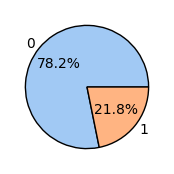

In [4]:
# Check the balance of target column loan_status
plt.figure(figsize=(2,2))
df['loan_default_status'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=sns.color_palette('pastel'),
                                       wedgeprops={'edgecolor': 'black', 'linewidth': 1})
plt.show()

The target variable loan_default_status is imbalanced, with 78.2% of applicants belonging to class 0 and only 21.8% belonging to class 1. This indicates that most loan were repaid. This imbalance needs to be addressed, else machine learning models may become biased toward predicting the majority class (0), resulting in lower performance when identifying approved loans (class 1).

### Data Cleaning

In [5]:
# Fill the missing values of person_emp_length with its median
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())

In [6]:
# Fill the missing loan_int_rate with the median int_rate of the particular type
df['loan_int_rate'] = df.groupby('loan_intent')['loan_int_rate'].transform(lambda x: x.fillna(x.median()))

In [7]:
# Check for null values in each column after handling
null_count = df.isna().sum()
null_percent = round(null_count*100/len(df), 2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent[df_null_percent['Null Count']>0]

,Null Count,Null Percent


In [8]:
# Check and remove duplicate records
print("Number of Duplicate rows:", df.duplicated().sum())
if df.duplicated().sum()>0:
    df.drop_duplicates(inplace=True)
    print("Number of Duplicate rows after removing:", df.duplicated().sum())

Number of Duplicate rows: 165
Number of Duplicate rows after removing: 0


### Feature Engineering

In [9]:
# Create a column to find the credit history to age ratio
df['credit_hist_age_ratio'] = df['cb_person_cred_hist_length']/df['person_age']

In [10]:
# Create a column to find the employment stability ratio
df['employment_stability_ratio'] = df['person_emp_length']/df['person_age']

### Exploratory Data Analysis

In [11]:
# Segregate the numerical, categorical columns from the target
num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 
            'loan_percent_income', 'cb_person_cred_hist_length', 'credit_hist_age_ratio', 
            'employment_stability_ratio']
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
target = ['loan_default_status']

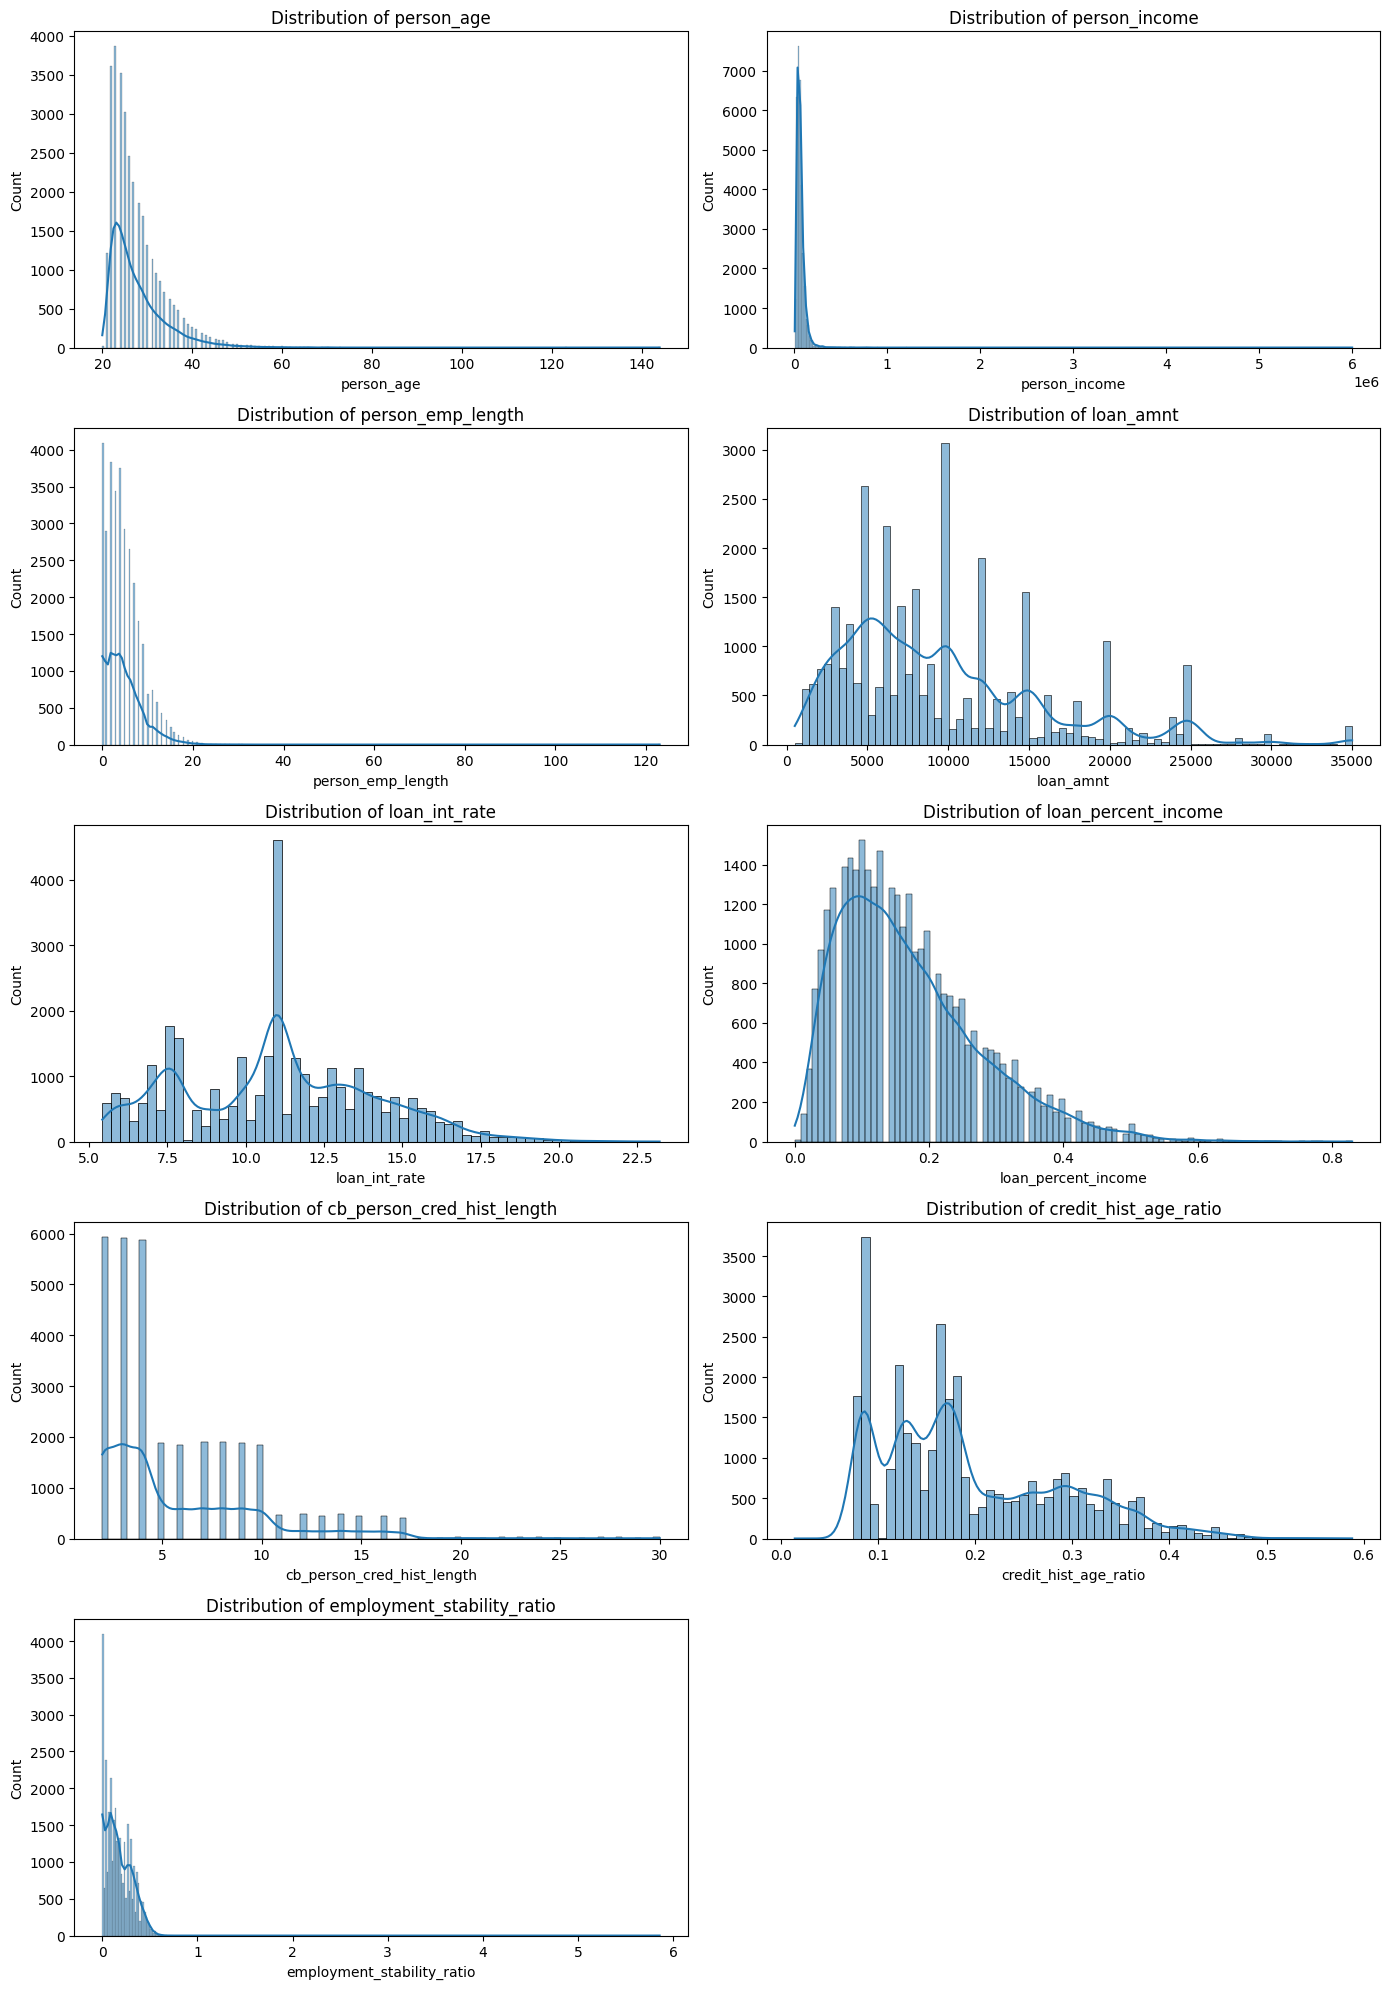

In [14]:
# Visualize the continous numerical columns using Histogram
no_of_rows = int((len(num_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Insights:
1. The age distribution is positively skewed, with most applicants between 20 and 35 years. A few extremely high ages are present, indicating potential outliers.
2. The income distribution is highly right-skewed. Most applicants have relatively lower incomes, while a small number of applicants have exceptionally high incomes, creating significant outliers.
3. Most applicants have fewer than 10 years of employment experience. The distribution is positively skewed with some extreme employment length values that may require further investigation.
4. Loan amounts are concentrated in the lower to mid-range values, with fewer applications requesting large loan amounts. The distribution shows moderate right skewness.
5. Interest rates are primarily distributed between 7% and 15%, with a peak around 11%. The distribution appears relatively balanced with slight positive skewness.
6. Most applicants allocate a small portion of their income toward loan repayment. The distribution is right-skewed, with a few applicants having very high loan-to-income ratios.
7. Most applicants have short credit histories, while fewer applicants possess long credit histories. The distribution is positively skewed with some high-value observations.
8. The employment_stability_ratio feature exhibits a highly right-skewed distribution with most borrowers having values below 0.5. A small number of extreme outliers were observed, indicating possible anomalies in employment length data.
9. The credit_hist_age_ratio feature measures the proportion of a borrower's lifetime represented by credit history. The feature shows a well-distributed range without major outliers and is expected to improve predictive performance by combining age and credit history into a single indicator of financial maturity.

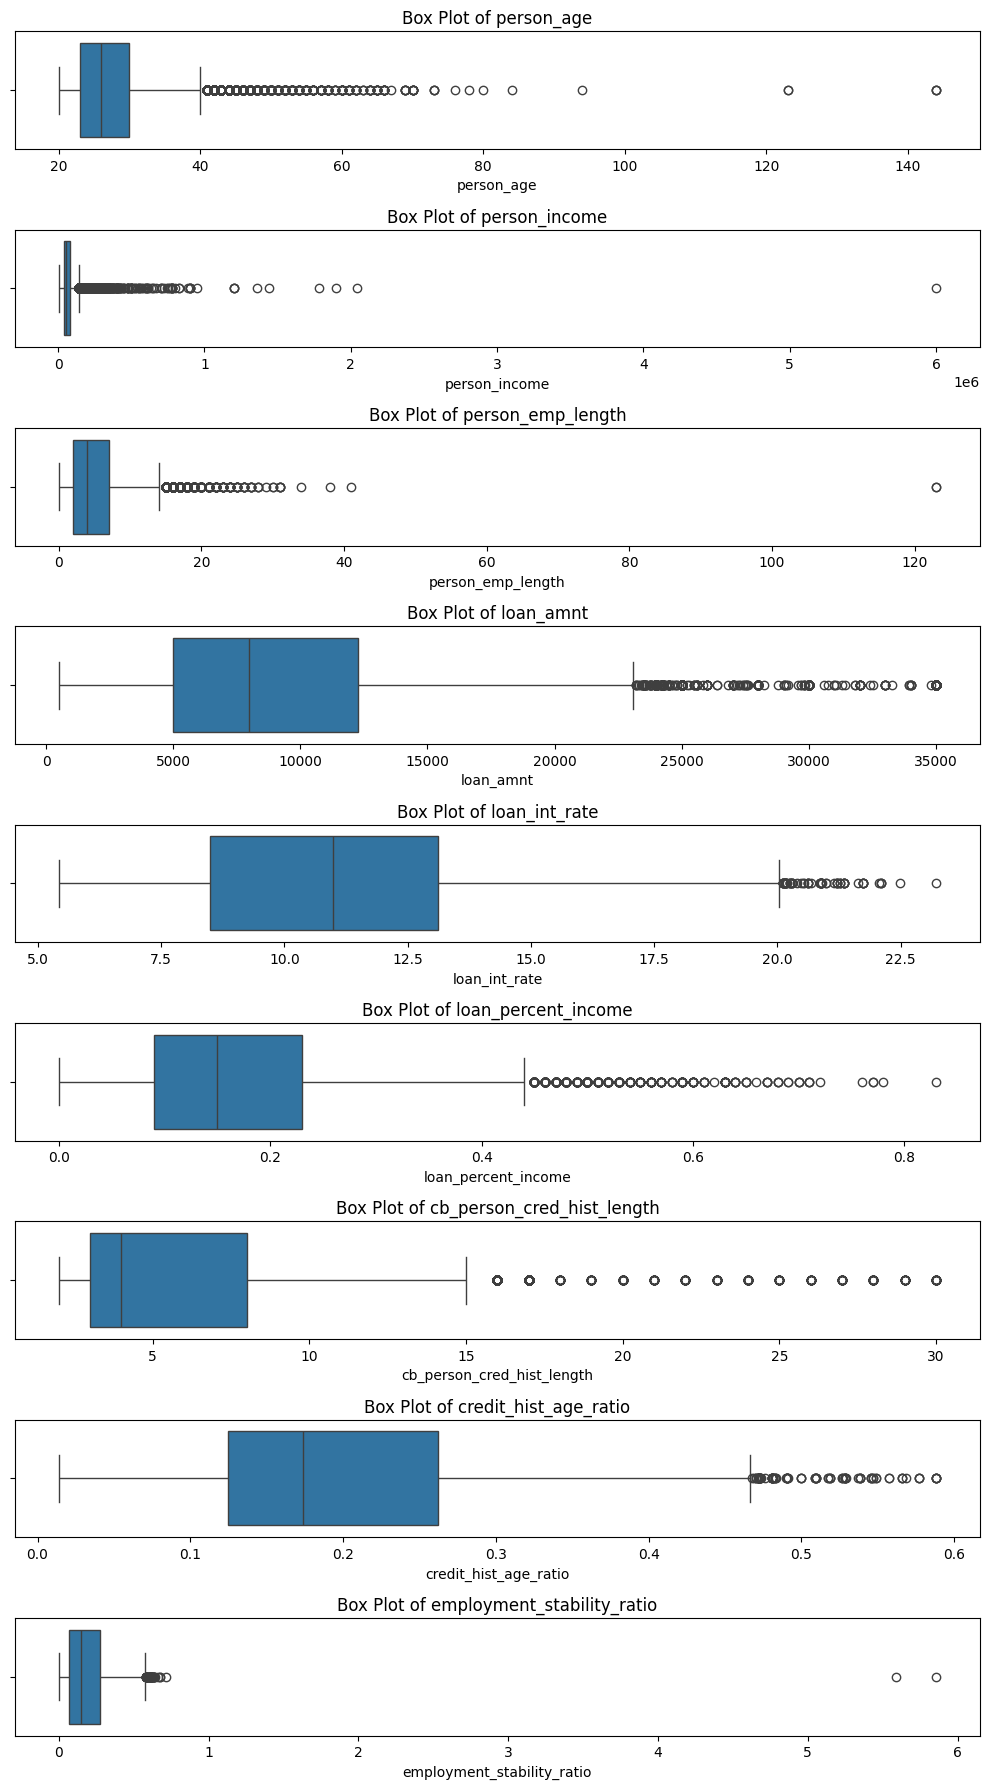

In [15]:
# Detect the outliers using boxplot
no_of_rows = len(num_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

There are some outliers which needs further investigation, such as person's age more than 100 years, employment years more than 50. These records will be investigated and correct in further steps.

In [12]:
# Find the records where person's age is more than 100
df[df['person_age']>=100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,credit_hist_age_ratio,employment_stability_ratio
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3,0.020833,0.027778
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2,0.013889,0.027778
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3,0.024390,0.016260
747,123,78000,RENT,7.0,VENTURE,B,20000,10.99,0,0.26,N,4,0.032520,0.056911
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25,0.173611,0.083333


The above ages of 123 and 144 seems erronous as there are very less chanses of their existance and requirement for loan. These data will be removed.

In [13]:
df = df[~(df['person_age']>=100)]

In [14]:
# Find the rocords where employment years is more than 50
df[df['person_emp_length']>=50]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,credit_hist_age_ratio,employment_stability_ratio
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,0.136364,5.590909
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4,0.190476,5.857143


These records seems to be erronous as it is impossible to have people with employment years like 123. These will be removed.

In [15]:
df = df[~(df['person_emp_length']>=50)]

In [16]:
# Find the customers whose age is less than 15 years plus their employmnet years
df[df['person_age']-df['person_emp_length']<15]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,credit_hist_age_ratio,employment_stability_ratio


In [17]:
# Check if there is any minor as they are not eligible for loan
df[df['person_age']<18]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_default_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,credit_hist_age_ratio,employment_stability_ratio


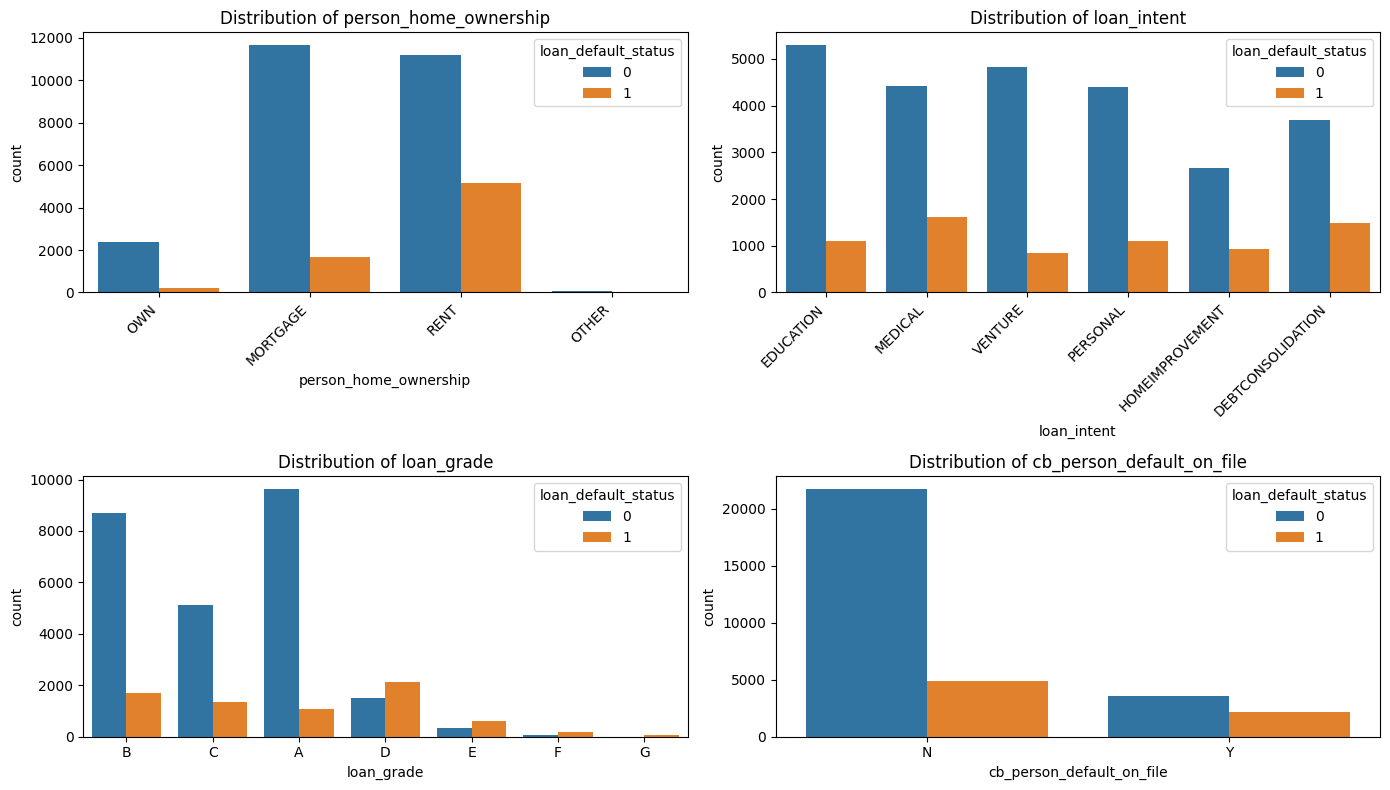

In [27]:
# Visualize the categorical columns using Countplot
no_of_rows = int((len(cat_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i], hue='loan_default_status')
    axes[i].set_title(f'Distribution of {col}')
    if col in ['person_home_ownership', 'loan_intent']:
        plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Insights:
1. Applicants with MORTGAGE and RENT statuses make up the majority of loan applications. The proportion of loan defaults appears highest among applicants living in RENT accommodations, while OWN and OTHER categories show relatively fewer defaults.
2. Loan applications are distributed across different purposes, with EDUCATION, VENTURE, and MEDICAL being the most common. The default rate appears relatively higher for MEDICAL and DEBTCONSOLIDATION loans compared to other loan purposes.
3. Better loan grades (A and B) are associated with a larger number of non-defaulted loans, whereas lower grades (D, E, F, and G) show a noticeably higher proportion of defaults. This suggests that loan grade is an important predictor of loan status.
4. Applicants with no previous default history (N) constitute the majority of borrowers and exhibit lower default rates. Borrowers with a previous default history (Y) show a relatively higher likelihood of loan default, indicating that past credit behavior strongly influences future loan outcomes.

### Feature Selection

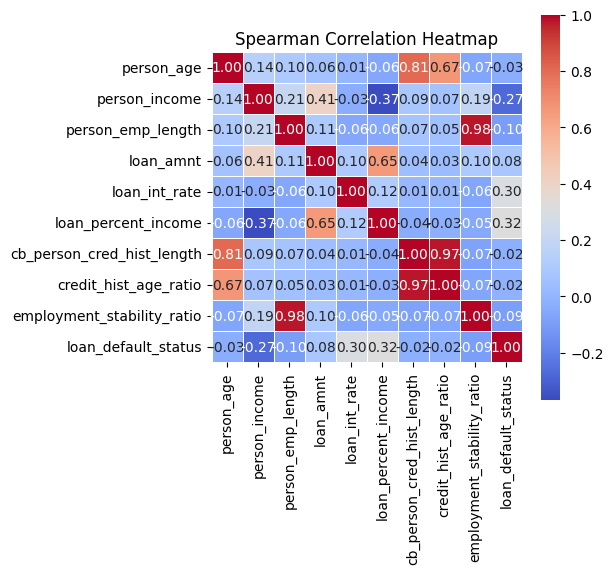

In [28]:
# Using Correlation Heatmap, find the relation between numerical columns and target
plt.figure(figsize=(5,5))
corr_matrix = df[num_cols+target].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Spearman Correlation Heatmap')
plt.show()

The Spearman correlation analysis indicates that loan_percent_income (0.32), loan_int_rate (0.30), and person_income (-0.27) exhibit the strongest relationships with loan defaults among the numerical variables. Overall, most numerical variables show weak to moderate correlations with the target variable, indicating that further analysis using categorical features and model-based feature importance is required to identify the most influential predictors.

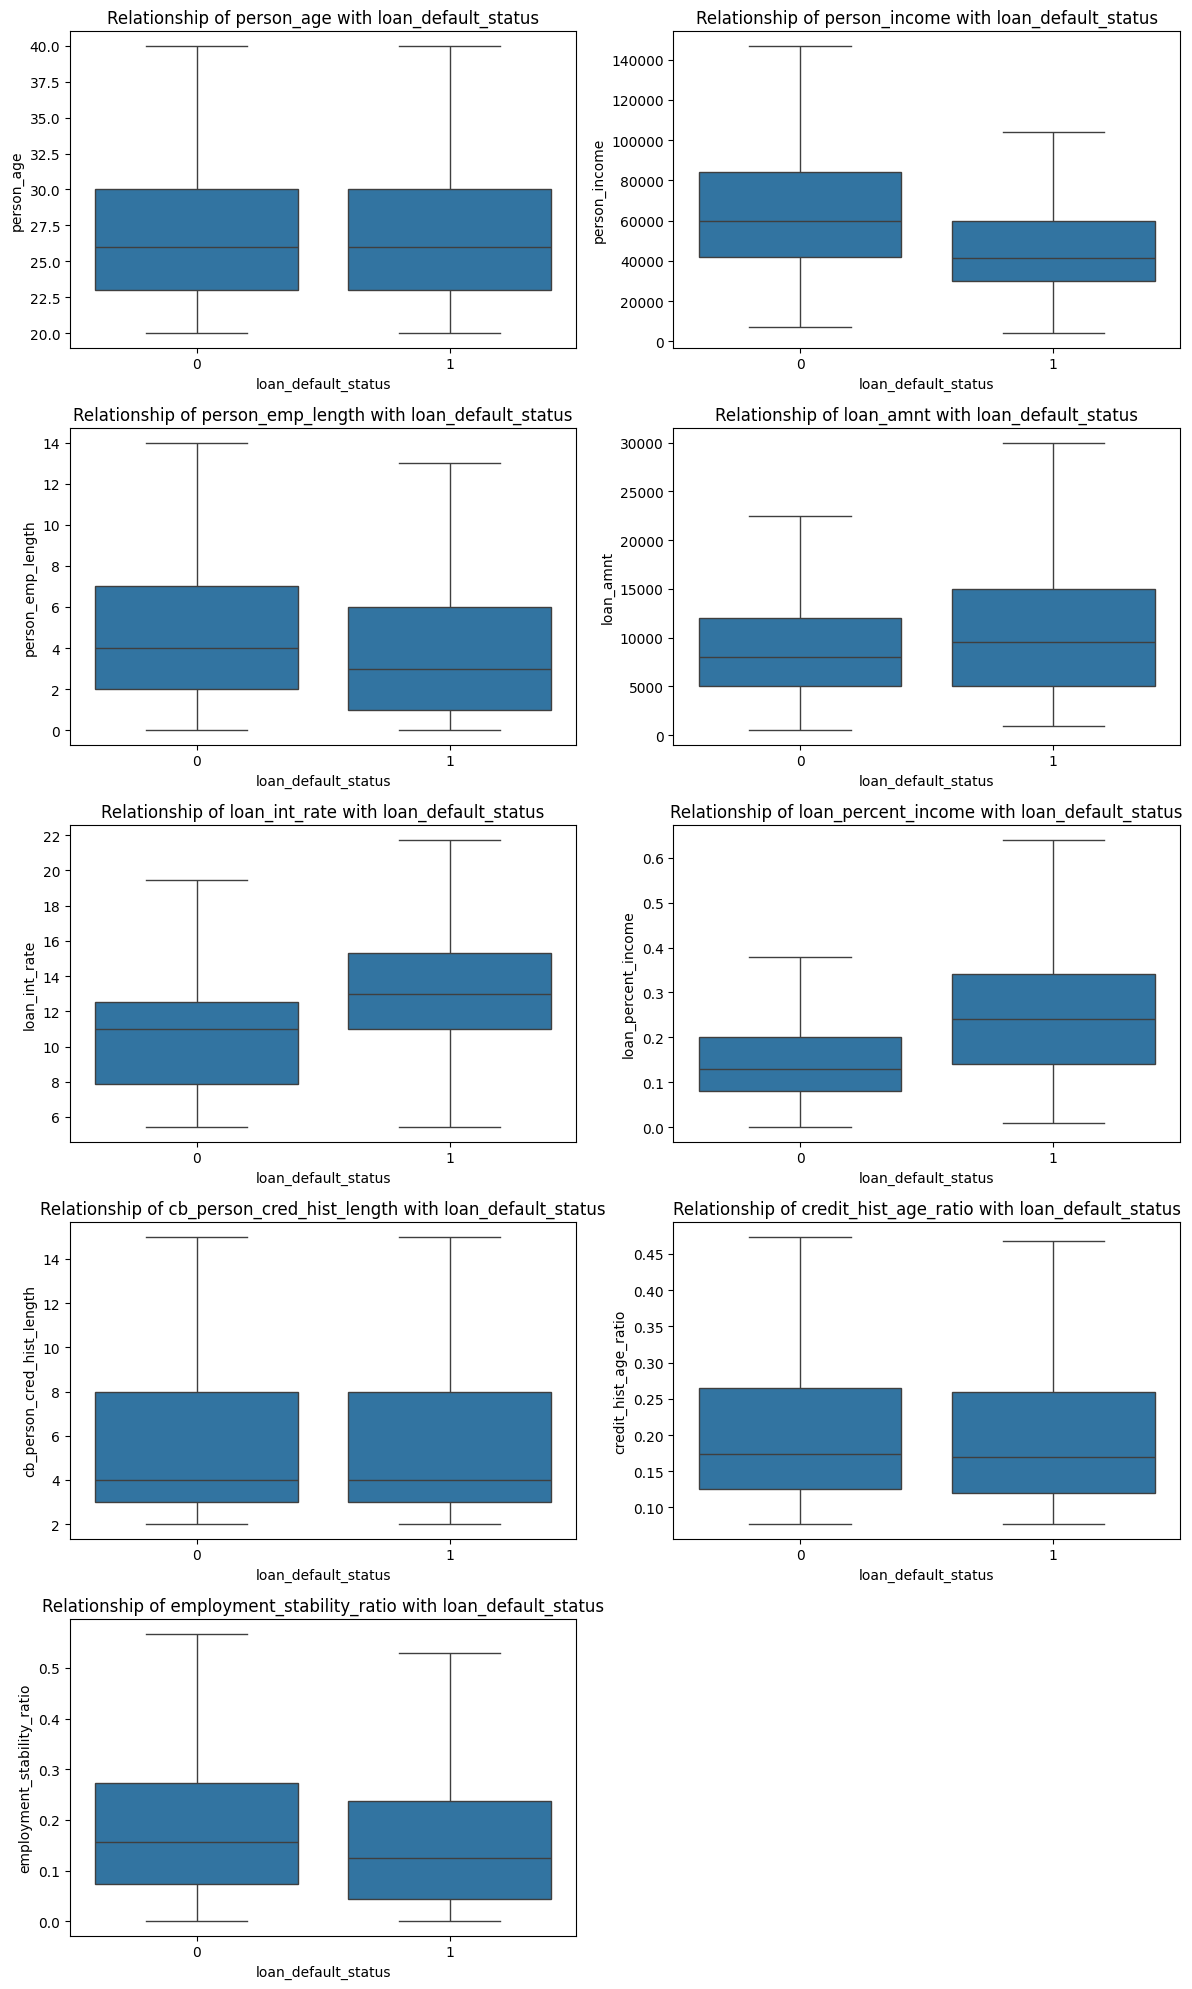

In [29]:
# Using boxplot, find the relation of each numerical feature with target
no_of_rows = (len(num_cols)+1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(12, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df[num_cols+target], x=target[0], y=col, showfliers=False, ax=axes[i])
    axes[i].set_title(f'Relationship of {col} with loan_default_status')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

#### Relationship Insights:
1. Person Age: Age distributions are nearly identical across defaulted and non-defaulted borrowers, indicating a weak relationship with loan default.
2. Person Income: Non-defaulted borrowers generally have higher incomes, suggesting that higher income is associated with lower default risk.
3. Employment Length: Borrowers with longer employment histories tend to exhibit lower default rates, indicating that employment stability may reduce credit risk.
4. Loan Amount: Defaulted borrowers tend to have slightly higher loan amounts; however, the difference is relatively small, suggesting limited predictive power.
5. Loan Interest Rate: Defaulted loans have noticeably higher interest rates than non-defaulted loans, making interest rate an important predictor of default.
6. Loan Percent Income: Borrowers with higher loan-to-income ratios are more likely to default, indicating that repayment burden is strongly associated with loan risk.
7. Credit History Length: Credit history length shows little variation between defaulted and non-defaulted borrowers, suggesting a weak relationship with loan default.
8. Credit History to Age Ratio: This feature shows no variation between defaulted and non-defaulted borrowers, suggesting no relationship with loan default.
9. Employment Stability Ratio: The employment stability ratio shows some variation between defaulted and non-defaulted borrowers, suggesting a moderately weak relationship with loan default.

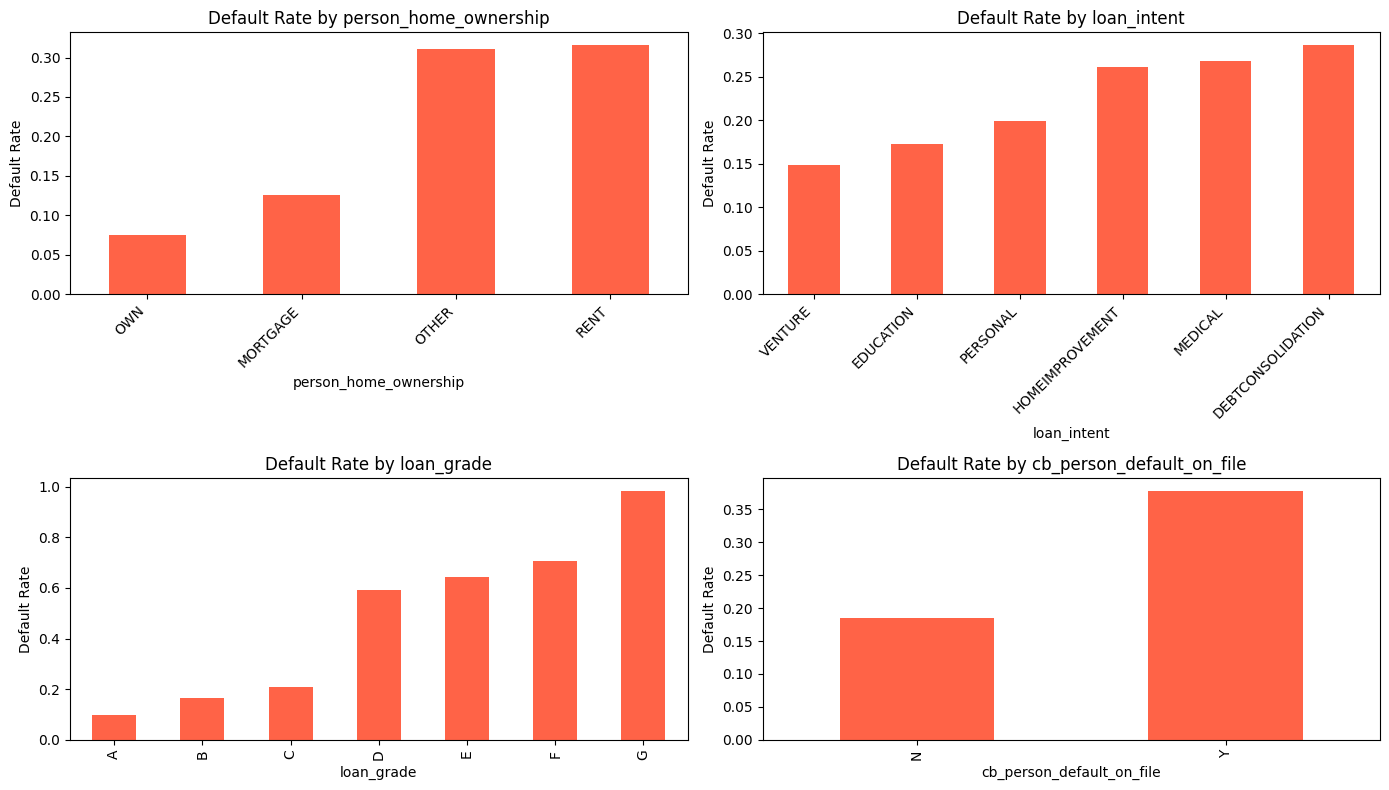

In [23]:
# Using crosstab, find the default rate among the various categorical columns
no_of_rows = int((len(cat_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    default_rate = pd.crosstab(df[col], df['loan_default_status'], normalize='index')
    default_rate[1].sort_values().plot(kind='bar', color='tomato', ax=axes[i])
    axes[i].set_title(f'Default Rate by {col}')
    axes[i].set_ylabel('Default Rate')
    if col in ['person_home_ownership', 'loan_intent']:
        plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Relationship Insights:
1. The default rate varies across home ownership categories. Borrowers who own their homes have the lowest default rate, while borrowers living in rented accommodations exhibit the highest default rate. This suggests that home ownership status may be an important indicator of credit risk.

2. Default rates differ across loan purposes. Loans taken for debt consolidation have the highest default rate, whereas venture loans have the lowest default rate. This indicates that the purpose of borrowing may influence repayment behavior.

3. The default rate increases consistently as loan grade deteriorates. Grade A loans have the lowest default rate, while Grade G loans have the highest default rate. This demonstrates a strong relationship between loan quality and default risk, making loan grade one of the most important predictors of loan default.

4. Borrowers with a previous default history exhibit a substantially higher default rate than borrowers with no prior defaults. This suggests that past credit behavior is a strong indicator of future loan repayment performance.

In [18]:
# Create the final dataframe with required features
features_to_keep = ['person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 
                    'person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file', 
                    'employment_stability_ratio', 'loan_default_status']
df_final = df[features_to_keep]
df_final.head()

,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,person_home_ownership,loan_intent,loan_grade,cb_person_default_on_file,employment_stability_ratio,loan_default_status
1,9600,5.0,1000,11.14,0.10,OWN,EDUCATION,B,N,0.238095,0
2,9600,1.0,5500,12.87,0.57,MORTGAGE,MEDICAL,C,N,0.040000,1
3,65500,4.0,35000,15.23,0.53,RENT,MEDICAL,C,N,0.173913,1
4,54400,8.0,35000,14.27,0.55,RENT,MEDICAL,C,Y,0.333333,1
5,9900,2.0,2500,7.14,0.25,OWN,VENTURE,A,N,0.095238,1


In [19]:
# Segregate the type of clumns to be sent to pipeline
numeric_cols = ['person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 
                'employment_stability_ratio']
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

### Train Test Split

In [20]:
# Segreggate the input and output data
x = df_final.drop(columns='loan_default_status')
y = df_final['loan_default_status']

In [21]:
# Train Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)

### Handle Class Imbalance

In [22]:
# Calculate the class weights
neg, pos = np.bincount(y_train)
scale_weight = neg/pos
print('Scale Weight', scale_weight.round(2))

Scale Weight 3.57


### Data Preprocessing

In [23]:
# Build a pipeline for data preprocessing of Logistic Regression
prepr_lr = ColumnTransformer(transformers=[('num', Pipeline([('scaler', StandardScaler())]), numeric_cols), 
                                           ('cat', Pipeline([('onehot', OneHotEncoder())]), categorical_cols)])

In [30]:
# Build a pipeline for data preprocessing of XG Boost Classifier
prepr_xgb = ColumnTransformer(transformers=[('cat', Pipeline([('onehot', OneHotEncoder())]), categorical_cols)])

### Model Training

In [24]:
# Train the data with Logistic Regression
lr_model = Pipeline([('preprocessor', prepr_lr), ('classifier', LogisticRegression(class_weight='balanced'))])
lr_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_income','person_emp_length','loan_amnt',...,'loan_grade', 'cb_person_default_on_file','employment_stability_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [32]:
# Train the data with XG Boost Classifier
xgb_model = Pipeline([('preprocessor', prepr_xgb), 
                      ('classifier', XGBClassifier(scale_pos_weight=scale_weight, random_state=42, 
                                                   eval_metric='logloss'))])
xgb_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_income','person_emp_length','loan_amnt',...,'loan_grade', 'cb_person_default_on_file','employment_stability_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By 

### Model Evaluation

In [25]:
# Create a function to evaluate any model
def model_results(name, model, x_train, y_train, x_test, y_test, threshold=0.5):
    # Predict results using probabilities
    y_prob = model.predict_proba(x_test)[:,1]
    y_pred = (y_prob >= threshold).astype(int)

    # Calculate the accuracy metrics
    accuracy = round(accuracy_score(y_test, y_pred)*100, 2)
    precision = round(precision_score(y_test, y_pred, zero_division=0)*100, 2)
    recall = round(recall_score(y_test, y_pred, zero_division=0)*100, 2)
    f1 = round(f1_score(y_test, y_pred, zero_division=0)*100, 2)

    # Check for fitting
    train_score = round(model.score(x_train, y_train)*100, 2)
    test_score = round(model.score(x_test, y_test)*100, 2)
    fit = ('Good Fit' if abs(train_score-test_score)<5 else 
           'Slight Overfit' if abs(train_score-test_score)<10 else 
           'Overfit')
    
    # Calculate the ROC-AUC
    if hasattr(model, "predict_proba"):
        roc_auc = round(roc_auc_score(y_test, y_prob) * 100, 2)
    else:
        roc_auc = None

    # Cross Validation ROC-AUC
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_auc = cross_val_score(model, x_train, y_train, cv=cv, scoring='roc_auc').mean()
    cv_auc = round(cv_auc * 100, 2)
    
    return {'Model Name': name, 'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1 Score': f1, 
            'ROC-AUC': roc_auc, 'CV ROC-AUC': cv_auc, 'Train Score': train_score, 'Test Score': test_score, 'Fit': fit}

def model_confucion_matrix(name, model, x_test, y_test):
    # Predict the results
    y_pred = model.predict(x_test)

    # Display the confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(f'{name} Confusion Matrix')
    plt.show()

In [34]:
# Create a dictionary of trained models
models = {"Logistic Regression": lr_model, "XGBoost": xgb_model}

In [35]:
# Evaluate the results of all the models
results = [model_results(name, model, x_train, y_train, x_test, y_test) for name, model in models.items()]
results_df = pd.DataFrame(results)
results_df

,Model Name,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV ROC-AUC,Train Score,Test Score,Fit
0,Logistic Regression,80.64,53.97,78.14,63.84,87.16,87.03,81.30,80.64,Good Fit
1,XGBoost,71.14,40.64,69.39,51.26,80.09,79.92,72.32,71.14,Good Fit


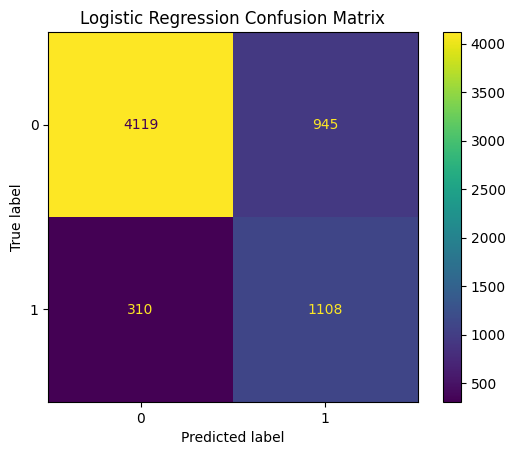

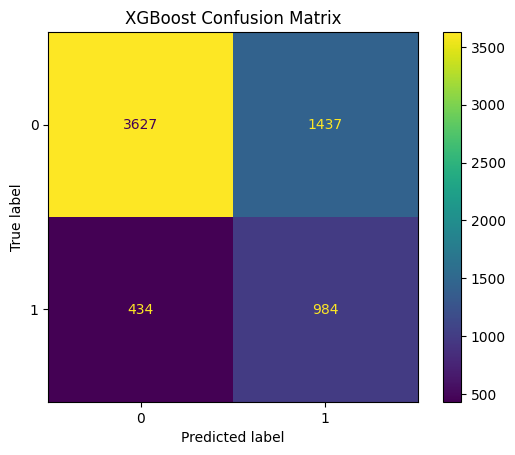

In [36]:
# Display the confusion matrices
models = {"Logistic Regression": lr_model, "XGBoost": xgb_model}
for name, model in models.items():
    model_confucion_matrix(name, model, x_test, y_test)

Among the evaluated models, Logistic Regression consistently outperformed XGBoost, achieving the highest Accuracy (80.64%), Precision (53.97%), Recall (78.14%), F1-Score (63.84%), and ROC-AUC (87.16%). The model also achieved a cross-validated ROC-AUC of 87.03%, which is very close to the test ROC-AUC, indicating strong generalization capability and stable performance across different data splits.

From a business perspective, the model's Recall of 78.14% is particularly important, as it successfully identifies a large proportion of potential loan defaulters. This helps financial institutions reduce lending risk by minimizing the number of high-risk borrowers incorrectly classified as safe applicants.

The model performance can be improved using hyperparameter tuning of both the models.

### Hyperparameter Tuning

In [26]:
# Find the best parameters of Logistic Regression using Grid Search CV
param_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(estimator=lr_model, param_grid=param_grid, scoring='roc_auc', cv=5, n_jobs=-1)
grid.fit(x_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best CV ROC-AUC:", grid.best_score_)

Best Parameters: {'classifier__C': 100}
Best CV ROC-AUC: 0.8703386707156529


In [27]:
# Train the model using the best parameters
lr_tuned = Pipeline([('preprocessor', prepr_lr), 
                     ('classifier', LogisticRegression(C=100, class_weight='balanced', max_iter=1000, 
                                                       random_state=42))])
lr_tuned.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_income','person_emp_length','loan_amnt',...,'loan_grade', 'cb_person_default_on_file','employment_stability_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of `

In [39]:
# Find the best parameters of XGBoost Classifier using Randomized Search CV
param_grid = {'classifier__n_estimators': randint(150, 600), 'classifier__max_depth': randint(3, 9), 
              'classifier__learning_rate': uniform(0.01, 0.5), 'classifier__subsample': uniform(0.6, 0.4), 
              'classifier__colsample_bytree': uniform(0.6, 0.4), 'classifier__min_child_weight': randint(1, 10), 
              'classifier__gamma': uniform(0, 5)}
random = RandomizedSearchCV(xgb_model, param_grid, n_iter=150, cv=5, scoring='roc_auc', n_jobs=-1, 
                                   verbose=1)
random.fit(x_train, y_train)
print("Best Parameters:", random.best_params_)
print("Best CV ROC-AUC:", random.best_score_)

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Best Parameters: {'classifier__colsample_bytree': np.float64(0.9759599719493344), 'classifier__gamma': np.float64(3.124159890157789), 'classifier__learning_rate': np.float64(0.26373493285989635), 'classifier__max_depth': 3, 'classifier__min_child_weight': 4, 'classifier__n_estimators': 400, 'classifier__subsample': np.float64(0.8230740112990684)}
Best CV ROC-AUC: 0.8019043562567207


In [40]:
# Train the model using the best parameters
xgb_tuned = Pipeline([('preprocessor', prepr_xgb), 
                     ('classifier', XGBClassifier(scale_pos_weight=scale_weight, random_state=42, 
                                                  eval_metric='logloss', colsample_bytree=0.976, gamma=3.124, 
                                                  learning_rate=0.264, max_depth=3, min_child_weight=4, 
                                                  n_estimators=400, subsample=0.823))])
xgb_tuned.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_income','person_emp_length','loan_amnt',...,'loan_grade', 'cb_person_default_on_file','employment_stability_ratio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By 

In [49]:
# Create a dictionary of trained models and evaluate their results
models = {"Logistic Regression": lr_model, "XGBoost Classifier": xgb_model, 
          "Tuned Logistic Regression": lr_tuned, "Tuned XGBoost Classifier": xgb_tuned}
results = [model_results(name, model, x_train, y_train, x_test, y_test) for name, model in models.items()]
results_df = pd.DataFrame(results)
results_df

,Model Name,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV ROC-AUC,Train Score,Test Score,Fit
0,Logistic Regression,80.64,53.97,78.14,63.84,87.16,87.03,81.30,80.64,Good Fit
1,XGBoost Classifier,71.14,40.64,69.39,51.26,80.09,79.92,72.32,71.14,Good Fit
2,Tuned Logistic Regression,80.64,53.97,78.07,63.82,87.16,87.03,81.29,80.64,Good Fit
3,Tuned XGBoost Classifier,70.69,40.38,71.37,51.58,80.19,80.14,71.25,70.69,Good Fit


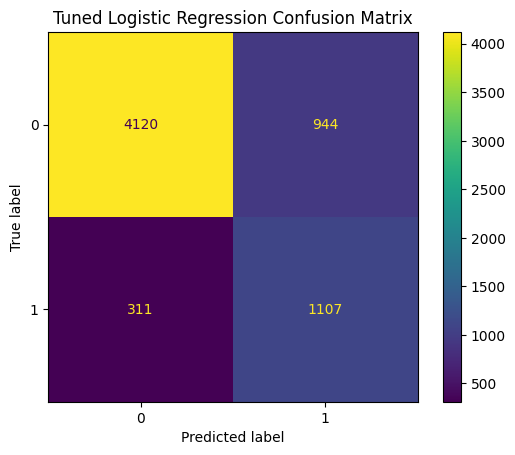

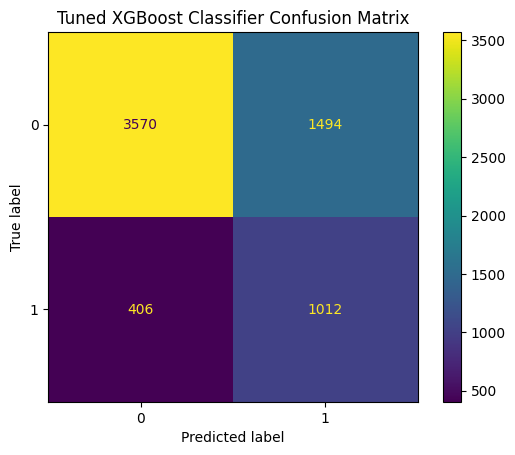

In [42]:
# Display the confusion matrices of the tuned models
models = {"Tuned Logistic Regression": lr_tuned, "Tuned XGBoost Classifier": xgb_tuned}
for name, model in models.items():
    model_confucion_matrix(name, model, x_test, y_test)

### Model Conclusion
Logistic Regression consistently outperformed both the baseline and tuned XGBoost models across all evaluation metrics. The model achieved an Accuracy of 80.64%, Recall of 78.14%, F1-Score of 63.84%, and ROC-AUC of 87.16%, demonstrating strong predictive performance and excellent discrimination between defaulters and non-defaulters. 

Hyperparameter tuning produced negligible improvement, indicating that the original Logistic Regression model was already close to optimal for the given feature set. The close alignment between train, test, and cross-validation scores confirms that the model generalizes well without overfitting. 

Therefore, Logistic Regression was selected as the final model for loan default prediction due to its superior performance, stability, and interpretability.

### Threshold Optimization

Classification models use a default threshold of 0.5 to predict loan defaults, but this may not balance Precision and Recall effectively. 

In banking, identifying more defaulters is prioritized to avoid lending to risky borrowers, even if some genuine non-defaulters are filtered out. 

Threshold optimization tests different probability cutoffs to maximize a metric such as the F1-Score, improving defaulter detection without changing the underlying model.

#### Find the Optimal Threshold

In [28]:
# Predict probabilities
y_prob = lr_model.predict_proba(x_test)[:, 1]

# Calculate precision, recall and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# Calculate F1 Score for each threshold
f1_scores = ((2*precisions*recalls)/(precisions + recalls + 1e-10))

# Find best threshold
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]

print("Best Threshold:", round(best_threshold, 4))
print("Best Precision:", round(precisions[best_idx], 4))
print("Best Recall:", round(recalls[best_idx], 4))
print("Best F1 Score:", round(f1_scores[best_idx], 4))

Best Threshold: 0.6843
Best Precision: 0.6953
Best Recall: 0.6615
Best F1 Score: 0.678


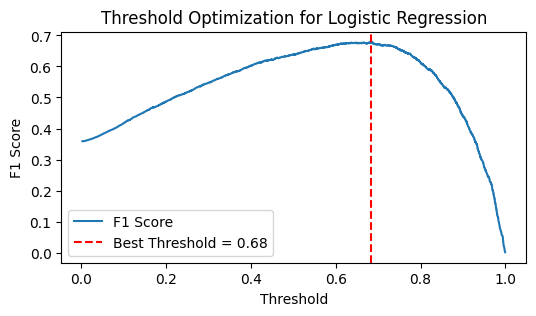

In [29]:
# Plot Threshold vs F1 Score
plt.figure(figsize=(6,3))
plt.plot(thresholds, f1_scores[:-1], label='F1 Score')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('Threshold Optimization for Logistic Regression')
plt.legend()
plt.show()

In [30]:
# Compare the results between the best model with and without threshold
threshold = {"Logistic Regression (threshold=0.5)": 0.5, "Logistic Regression (threshold=0.68)": 0.68}
thresholds_results = [model_results(name, lr_model, x_train, y_train, x_test, y_test, threshold_value) 
                      for name, threshold_value in threshold.items()]
thresholds_results_df = pd.DataFrame(thresholds_results)
thresholds_results_df

,Model Name,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV ROC-AUC,Train Score,Test Score,Fit
0,Logistic Regression (threshold=0.5),80.64,53.97,78.14,63.84,87.16,87.03,81.3,80.64,Good Fit
1,Logistic Regression (threshold=0.68),86.12,68.96,66.43,67.67,87.16,87.03,81.3,80.64,Good Fit


#### Conclusion
Threshold optimization was performed to identify the probability cutoff that maximized the F1-Score. The optimal threshold was found to be 0.6843, resulting in an F1-Score of 67.8%. However, this threshold reduced Recall from 78.14% to 66.15%. 

Since the primary objective of the project is to identify potential loan defaulters, the default threshold of 0.5 was retained to maximize Recall and minimize the risk of misclassifying high-risk borrowers as low-risk applicants.

### Final Model Conclusion

A comparative analysis of Logistic Regression and XGBoost was performed to predict loan default risk. Among all models evaluated, Logistic Regression delivered the best overall performance and demonstrated strong generalization on unseen data.

#### 📊 Final Model Selected: Logistic Regression (Threshold = 0.50)

| Accuracy | Precision | Recall | F1-Score | ROC-AUC | 5-Fold CV ROC-AUC |
|----------|-----------|--------|----------|---------|-------------------|
| 80.64%   | 53.97%    | 78.14% | 63.84%   | 87.16%  | 87.03%            |

#### 🔍 Key Observations
1. Logistic Regression consistently outperformed both the baseline and tuned XGBoost models.
2. Feature engineering and hyperparameter tuning resulted in only marginal improvements, indicating that the original features already captured most of the predictive information.
3. Threshold optimization increased Accuracy and F1-Score at a threshold of 0.68, but reduced Recall significantly.
4. Since the primary objective is to identify potential defaulters, maintaining a higher Recall is more important than maximizing Accuracy.

#### 💼 Business Interpretation
In loan default prediction, missing a potential defaulter (False Negative) is generally more costly than incorrectly flagging a safe borrower (False Positive). Therefore, Recall is a critical metric.

Although the optimized threshold improved F1-Score, the default threshold of 0.50 was retained because it identifies a higher proportion of defaulters and better supports the project's objective of minimizing lending risk.

#### 🎯 Final Decision
Logistic Regression with a threshold of 0.50 was selected as the final model because it provides the best balance of predictive performance, stability, interpretability, and business value for loan default prediction.

### SHAP Analysis

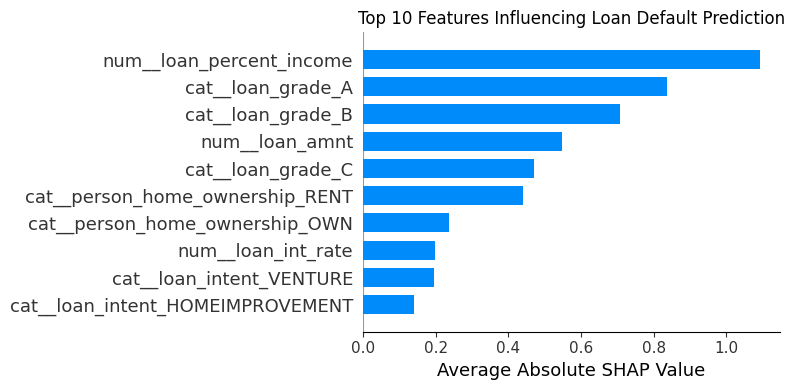

In [31]:
# Extract transformed data
x_train_transformed = (lr_model.named_steps['preprocessor'].transform(x_train))

# Define the background sample
background = shap.sample(x_train_transformed, 99, random_state=42)

# Create SHAP explainer
explainer = shap.LinearExplainer(lr_model.named_steps['classifier'], background)

# Calculate SHAP values
shap_values = explainer.shap_values(x_train_transformed)
feature_names = lr_model.named_steps['preprocessor'].get_feature_names_out()

# Plot the summary graph
shap.summary_plot(shap_values, x_train_transformed, feature_names=feature_names, plot_type='bar', 
                  max_display=10, show=False)
plt.gcf().set_size_inches(8, 4)
plt.title('Top 10 Features Influencing Loan Default Prediction')
plt.xlabel('Average Absolute SHAP Value')
plt.tight_layout()
plt.show()

SHAP analysis identified loan_percent_income as the most influential feature in predicting loan defaults, indicating that borrowers using a larger share of their income to service loans are more likely to default. 

Loan grade, loan amount, home ownership status, and interest rate were also among the most significant predictors. 

Overall, the results suggest that borrower affordability and loan risk characteristics are the primary drivers of default behavior.

### Model Deployment

In [32]:
# Create the pickle file of the model
joblib.dump(lr_model, 'credit_risk_predictor_model.pkl')

['credit_risk_predictor_model.pkl']